# Codiagnosticabilidad

Se define el autómata $G_B$ con el evento de falla no observable $f$ y se tienen dos sitios no comunicados para el diagnóstico de fallas

| Diagnosticador | $E_o$ | $E_{uo}$ |
|---|---|---|
| $Diag_1(G_B)$ | $\{a, c\}$ | $\{b, f\}$ |
| $Diag_2(G_B)$ | $\{b, c\}$ | $\{a, f\}$ |

In [1]:
#@title Instalación de DESlab desde GitHub (solo en Colab)
import shutil, subprocess

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q git+https://github.com/nebisman/deslab-py3.git

Note: you may need to restart the kernel to use updated packages.


In [26]:
from deslab import *

## 1. Autómata $G_B$

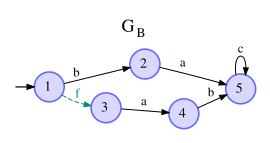

In [27]:
syms('a b c f')
X = [1, 2, 3, 4, 5]
E = [a, b, c, f]
T = [(1, f, 3), (1, b, 2), (3, a, 4), (4, b, 5), (2, a, 5), (5, c, 5)]

GB = fsa(X, E, T, [1], [], Sigobs=[a,b,c], name='$G_B$')
draw(GB)

## 2. $Diag_1(G_B)$ con $E_o = \{a, c\}$

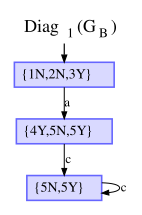

In [28]:
Diag1 = diagnoser(GB, f, [a, c])
draw(Diag1.setpar(name='$Diag_1(G_B)$'))

## 3. $Diag_2(G_B)$ con $\Sigma_o = \{b, c\}$

Ahora $a$ y $f$ no son observables además de la falla

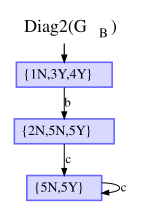

In [29]:
Diag2 = diagnoser(GB, f, [b, c])
draw(Diag2.setpar(name='$Diag2(G_B)$'))

## Algoritmo de Moreira para codiagosticabilidad

In [30]:
def verifycodiagnosability(G, f):
    Euo1 = [b]
    Euo2 = [a]
    # Step 1.1
    G_N1 = G.deletevent(f)
    # Step 1.2
    GN = ac(G_N1)
    # Step 2.1
    Al = labelfailaut(f)
    # Step 2.2
    Gl = G // Al
    Xml = [(x, l) for (x, l) in Gl.X if l == 'Y']
    Gl = Gl.setpar(Xm=Xml)
    # Step 2.3
    GY = coac(Gl)
    # Step 3
    R1 = [(event, event + '_R') for event in Euo1]
    GN1 = renamevents(GN, R1)

    R2 = [(event, event + '_R') for event in Euo2]
    GN2 = renamevents(GN, R2)

    # Step 4
    GV = GN1 // GN2 // GY
    print(GV.X)
    XmV = [((xN1, xN2), (xY, l)) for ((xN1, xN2), (xY, l)) in GV.X if l == 'Y']
    GV = GV.setpar(Xm=XmV)
    GV.style='verifier'
    draw(GV.setpar(name="verificador"))
    # Step 5

    # We need to find the nontrivial SCCs
    SCC = strconncomps(GV.Graph)
    C_1 = selfloopnodes(GV.Graph)
    SCC_NT = [C for C in SCC if (len(C) > 1)] + [set([C]) for C in C_1]

    # we are searching for a counter-example
    C1 = []
    diagnosable = True
    for C in SCC_NT:
        for x_V in (C & GV.Xm):
            if (GV.Gamma(x_V) & G.Sigma) != set([]):
                diagnosable = False
                if C1 != C:
                    print(C)
                C1 = C
    return diagnosable

frozenset({((1, 1), (3, 'Y')), ((5, 2), (5, 'Y')), ((5, 5), (5, 'Y')), ((2, 1), (1, 'N')), ((2, 1), (3, 'Y')), ((5, 1), (4, 'Y')), ((1, 1), (1, 'N'))})


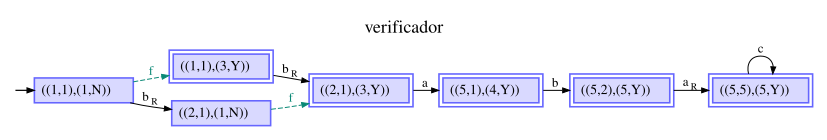

{((5, 5), (5, 'Y'))}


False

In [25]:
verifycodiagnosability(GB, f)

## 5. Observaciones

En ambos diagnosticadores aparece el estado incierto $\{5N, 5Y\}$ con un autolazo en $c$. Las secuencias
$b\,a\,c^n$ (normal) y $f\,a\,b\,c^n$ (con falla) producen la misma proyección en los dos casos
($a\,c^n$ con $\Sigma_o=\{a,c\}$ y $b\,c^n$ con $\Sigma_o=\{b,c\}$), así que ese ciclo es
**indeterminado** y la falla $f$ **no es diagnosticable** con ninguno de los dos conjuntos de eventos observables.